<a href="https://colab.research.google.com/github/Killeryoung/ML/blob/main/%D0%9B%D0%A08_%D0%93%D1%83%D1%80%D0%BA%D0%BE_%D0%A4%D0%86%D0%A2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [ ]:
iris = load_iris()
iris_df = pd.DataFrame(iris.data, columns=iris.feature_names)
display(iris_df.head())
iris_features = iris_df.iloc[:, :3]

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

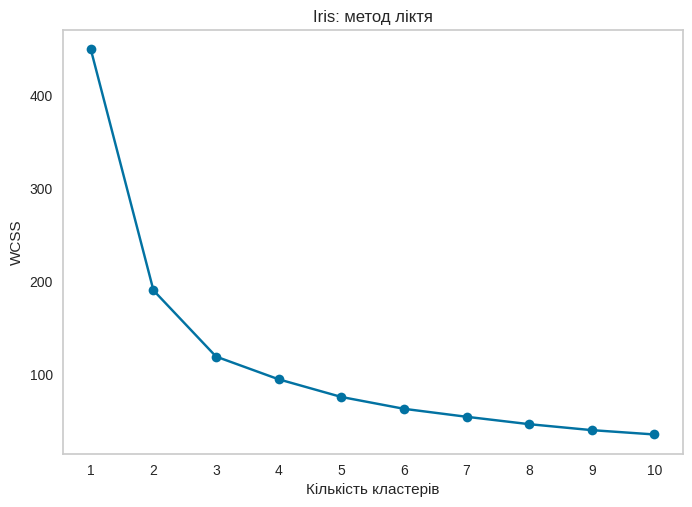

In [ ]:
iris_scaled = StandardScaler().fit_transform(iris_features)
ks = range(1, 11)
iris_wcss = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(iris_scaled).inertia_ for k in ks]
plt.plot(list(ks), iris_wcss, marker='o'); plt.xticks(list(ks)); plt.xlabel('Кількість кластерів'); plt.ylabel('WCSS'); plt.title('Iris: метод ліктя'); plt.grid(); plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

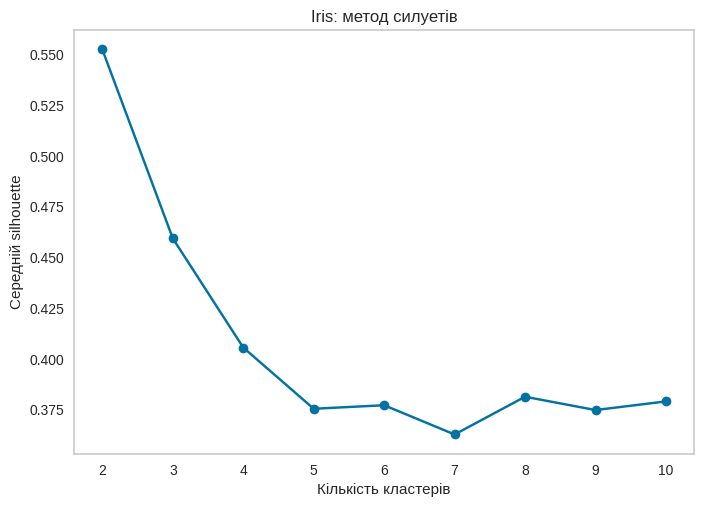

Найкраще k за силуетом: 2


In [ ]:
iris_sil = [silhouette_score(iris_scaled, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(iris_scaled)) for k in range(2, 11)]
plt.plot(range(2, 11), iris_sil, marker='o'); plt.xticks(range(2, 11)); plt.xlabel('Кількість кластерів'); plt.ylabel('Середній silhouette'); plt.title('Iris: метод силуетів'); plt.grid(); plt.show()
print('Найкраще k за силуетом:', range(2, 11)[int(__import__('numpy').argmax(iris_sil))])

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

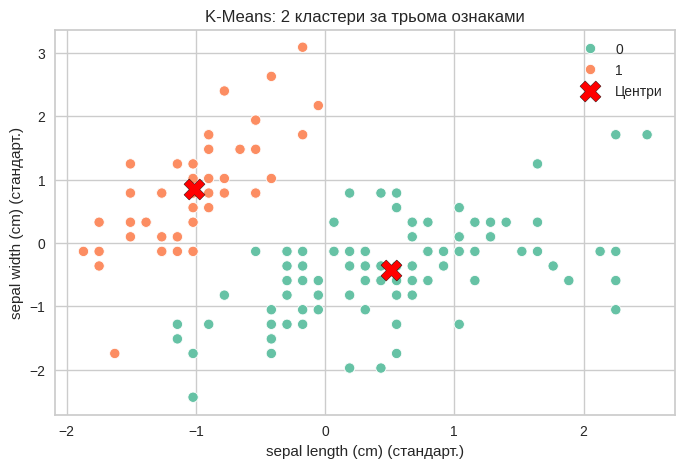

In [ ]:
iris_kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
iris_labels = iris_kmeans.fit_predict(iris_scaled)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=iris_scaled[:, 0], y=iris_scaled[:, 1], hue=iris_labels, palette='Set2', s=55)
plt.scatter(iris_kmeans.cluster_centers_[:, 0], iris_kmeans.cluster_centers_[:, 1], marker='X', s=230, c='red', edgecolors='black', label='Центри')
plt.xlabel(iris_features.columns[0] + ' (стандарт.)'); plt.ylabel(iris_features.columns[1] + ' (стандарт.)'); plt.title('K-Means: 2 кластери за трьома ознаками'); plt.legend(); plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

Метод ліктя визначає компроміс між кількістю кластерів і WCSS, а метод силуетів оцінює відокремленість груп. У роботі фінально використано `k=2` відповідно до умови. Порівняти це значення з максимумом графіка силуетів та вигином кривої WCSS після запуску: вони не обов'язково збігаються.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, silhouette_score
from sklearn.cluster import KMeans

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [ ]:
df = pd.read_csv(csv_path)
display(df.head())
print('Розмір:', df.shape)

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


Розмір: (2392, 15)


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [ ]:
print(df.columns.tolist())

['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [ ]:
print(df.isna().sum())

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [ ]:
print('Дублікати:', df.duplicated().sum())

Дублікати: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [ ]:
display(df.describe(include='all').T)

,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.500000,690.655244,1001.000000,1598.750000,2196.500000,2794.250000,3392.000000
Age,2392.0,16.468645,1.123798,15.000000,15.000000,16.000000,17.000000,18.000000
Gender,2392.0,0.510870,0.499986,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,2392.0,0.877508,1.028476,0.000000,0.000000,0.000000,2.000000,3.000000
ParentalEducation,2392.0,1.746237,1.000411,0.000000,1.000000,2.000000,2.000000,4.000000
StudyTimeWeekly,2392.0,9.771992,5.652774,0.001057,5.043079,9.705363,14.408410,19.978094
Absences,2392.0,14.541388,8.467417,0.000000,7.000000,15.000000,22.000000,29.000000
Tutoring,2392.0,0.301421,0.458971,0.000000,0.000000,0.000000,1.000000,1.000000
ParentalSupport,2392.0,2.122074,1.122813,0.000000,1.000000,2.000000,3.000000,4.000000
Extracurricular,2392.0,0.383361,0.486307,0.000000,0.000000,0.000000,1.000000,1.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [ ]:
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler_clf = StandardScaler()
X_train_scaled = scaler_clf.fit_transform(X_train)
X_test_scaled = scaler_clf.transform(X_test)
print('Навчальна:', X_train.shape, 'Тестова:', X_test.shape)

Навчальна: (1913, 13) Тестова: (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [ ]:
rf_search = GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), {'n_estimators': [100, 200], 'max_depth': [None, 10, 20], 'min_samples_split': [2, 5]}, cv=5, scoring='accuracy', n_jobs=-1)
rf_search.fit(X_train, y_train)
rf_accuracy = accuracy_score(y_test, rf_search.predict(X_test))
print('Параметри:', rf_search.best_params_, '\nCV accuracy:', rf_search.best_score_, '\nTest accuracy:', rf_accuracy)

Параметри: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200} 
CV accuracy: 0.9205487129714435 
Test accuracy: 0.9102296450939458


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [ ]:
lr_search = GridSearchCV(LogisticRegression(solver='saga', max_iter=5000, random_state=42), {'C': [0.01, 0.1, 1, 10], 'penalty': ['l1', 'l2']}, cv=5, scoring='accuracy', n_jobs=-1)
lr_search.fit(X_train_scaled, y_train)
lr_accuracy = accuracy_score(y_test, lr_search.predict(X_test_scaled))
print('Параметри:', lr_search.best_params_, '\nCV accuracy:', lr_search.best_score_, '\nTest accuracy:', lr_accuracy)

Параметри: {'C': 0.1, 'penalty': 'l1'} 
CV accuracy: 0.8024113843588097 
Test accuracy: 0.8183716075156576


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [ ]:
svm_search = GridSearchCV(SVC(), {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf'], 'gamma': ['scale', 'auto']}, cv=5, scoring='accuracy', n_jobs=-1)
svm_search.fit(X_train_scaled, y_train)
svm_accuracy = accuracy_score(y_test, svm_search.predict(X_test_scaled))
print('Параметри:', svm_search.best_params_, '\nCV accuracy:', svm_search.best_score_, '\nTest accuracy:', svm_accuracy)

Параметри: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'} 
CV accuracy: 0.8520648503820759 
Test accuracy: 0.8580375782881002


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [ ]:
results = pd.DataFrame({'Модель': ['Random Forest', 'Logistic Regression', 'SVM'], 'CV accuracy': [rf_search.best_score_, lr_search.best_score_, svm_search.best_score_], 'Test accuracy': [rf_accuracy, lr_accuracy, svm_accuracy]})
display(results.sort_values('CV accuracy', ascending=False))
best_name = results.loc[results['CV accuracy'].idxmax(), 'Модель']
best_search = {'Random Forest': rf_search, 'Logistic Regression': lr_search, 'SVM': svm_search}[best_name]
best_X_test = X_test if best_name == 'Random Forest' else X_test_scaled
print('Найкраща за CV:', best_name)
print(classification_report(y_test, best_search.predict(best_X_test), zero_division=0))

,Модель,CV accuracy,Test accuracy
0,Random Forest,0.920549,0.910230
2,SVM,0.852065,0.858038
1,Logistic Regression,0.802411,0.818372


Найкраща за CV: Random Forest
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

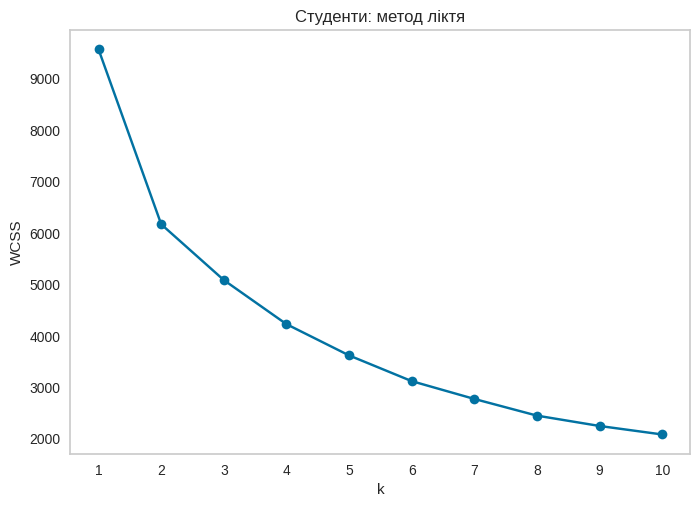

In [ ]:
student_cols = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
student_scaled = StandardScaler().fit_transform(df[student_cols])
student_wcss = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(student_scaled).inertia_ for k in range(1, 11)]
plt.plot(range(1, 11), student_wcss, marker='o'); plt.xticks(range(1, 11)); plt.xlabel('k'); plt.ylabel('WCSS'); plt.title('Студенти: метод ліктя'); plt.grid(); plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

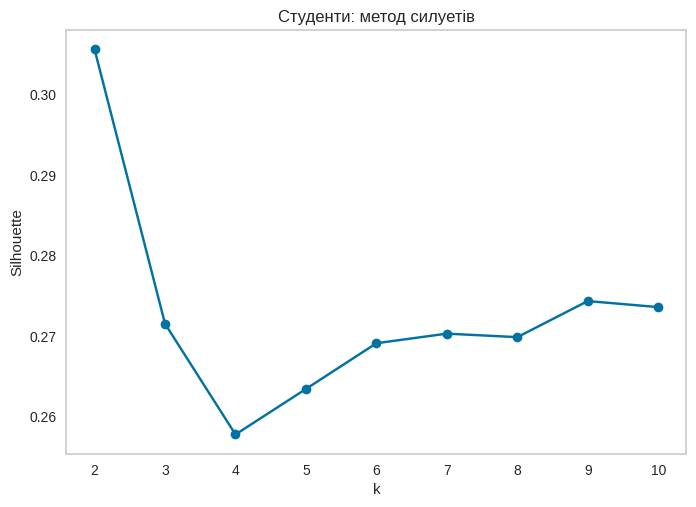

Оптимальне k за силуетом: 2


In [ ]:
student_sil = [silhouette_score(student_scaled, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(student_scaled), sample_size=min(1500, len(student_scaled)), random_state=42) for k in range(2, 11)]
plt.plot(range(2, 11), student_sil, marker='o'); plt.xticks(range(2, 11)); plt.xlabel('k'); plt.ylabel('Silhouette'); plt.title('Студенти: метод силуетів'); plt.grid(); plt.show()
print('Оптимальне k за силуетом:', np.argmax(student_sil) + 2)

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [ ]:
%pip -q install kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [ ]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [ ]:
X_pca = df.drop(columns=['StudentID', 'GradeClass'])
print('Ознаки PCA:', X_pca.columns.tolist())

Ознаки PCA: ['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA']


**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [ ]:
pca_scaler = StandardScaler()
X_pca_scaled = pca_scaler.fit_transform(X_pca)
pca_full = PCA().fit(X_pca_scaled)
explained = pca_full.explained_variance_ratio_
print('Частки дисперсії:', np.round(explained, 4))

Частки дисперсії: [0.1525 0.0861 0.0827 0.0807 0.0786 0.0779 0.0763 0.076  0.0744 0.0738
 0.0717 0.0675 0.0018]


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

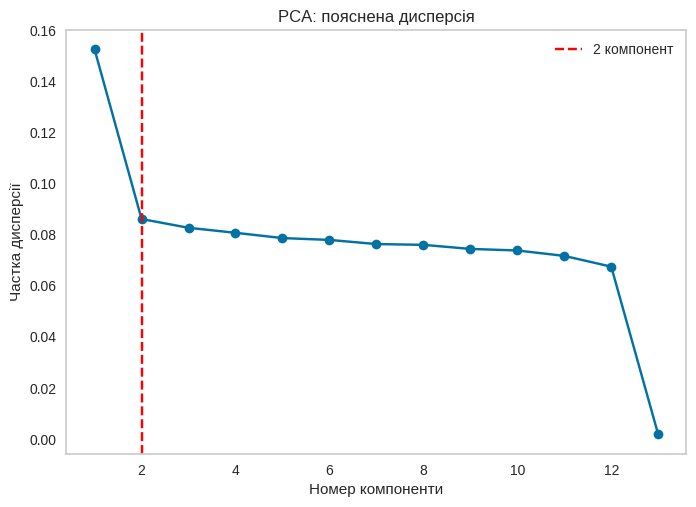

Обрана кількість компонент: 2


In [ ]:
components = np.arange(1, len(explained) + 1)
knee = KneeLocator(components, explained, curve='convex', direction='decreasing')
n_components = knee.knee if knee.knee is not None else int(np.searchsorted(np.cumsum(explained), 0.90) + 1)
plt.plot(components, explained, marker='o'); plt.axvline(n_components, color='red', linestyle='--', label=f'{n_components} компонент'); plt.xlabel('Номер компоненти'); plt.ylabel('Частка дисперсії'); plt.title('PCA: пояснена дисперсія'); plt.legend(); plt.grid(); plt.show()
print('Обрана кількість компонент:', n_components)

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

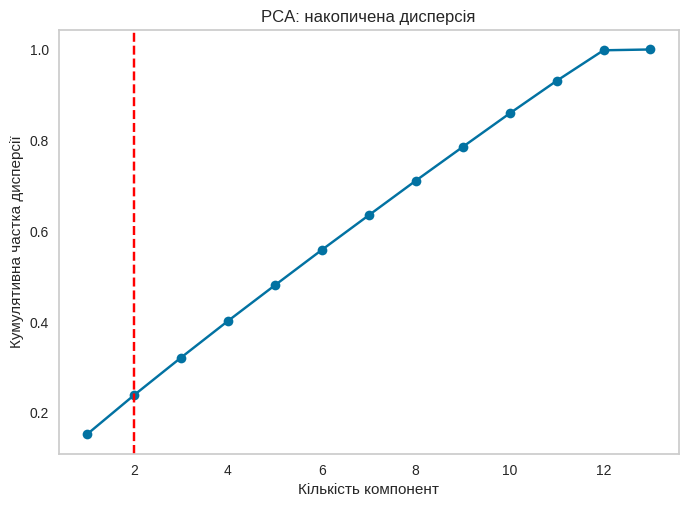

Пояснена дисперсія для 2 компонент: 23.86%
Форма даних після PCA: (2392, 2)


In [ ]:
cumulative = np.cumsum(explained)
plt.plot(components, cumulative, marker='o'); plt.axvline(n_components, color='red', linestyle='--'); plt.xlabel('Кількість компонент'); plt.ylabel('Кумулятивна частка дисперсії'); plt.title('PCA: накопичена дисперсія'); plt.grid(); plt.show()
print(f'Пояснена дисперсія для {n_components} компонент: {cumulative[n_components - 1]:.2%}')
pca = PCA(n_components=n_components)
X_reduced = pca.fit_transform(X_pca_scaled)
print('Форма даних після PCA:', X_reduced.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [ ]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

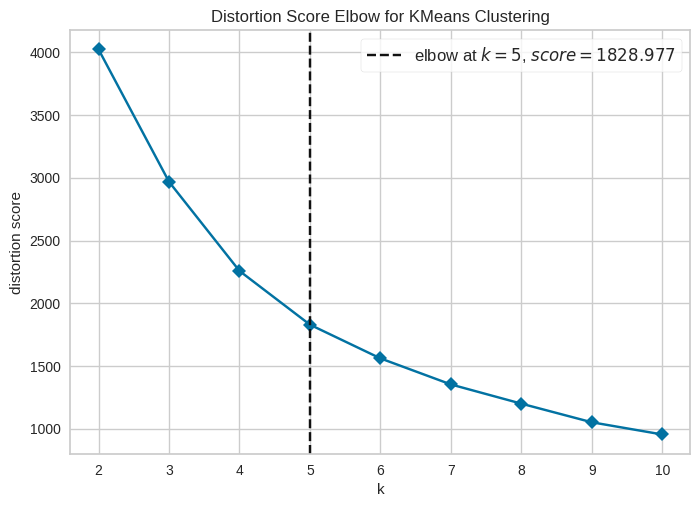

k за методом ліктя після PCA: 5


In [ ]:
visualizer = KElbowVisualizer(KMeans(random_state=42, n_init=10), k=(2, 11), timings=False)
visualizer.fit(X_reduced)
visualizer.show()
print('k за методом ліктя після PCA:', visualizer.elbow_value_)

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за GradeClass і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

У роботі виконано кластеризацію Iris за трьома ознаками та даних студентів за чотирма ознаками. Метод ліктя визначає кількість груп за зміною WCSS, а коефіцієнт силуета - за якістю розділення кластерів. Для Iris за умовою побудовано модель з двома кластерами.

У завданні 2 класифікація використовує відомі мітки `GradeClass` і прогнозує їх; кластеризація працює **без `GradeClass`** та шукає схожі групи студентів. Найкращий класифікатор обирається за середньою CV-точністю, а не за тестовою.